# Adding long-context history to transformers for simple control tasks

The purpose of this experiment notebook is to show off the value of making non-markovian policies for a simple task - PPO based learning to balance the cart-pole. To do this, we are going to define a very simple policy network that looks like a language model but the token space will be formed as such. 

$$z_0 = [ 0, s_0 ], \quad z_t=[a_{t-1}, s_t]$$

To accomodate a language model like setup, we can naively discretize the continuous action-state space $\mathcal{Z}$ via binning to form a token sequence space $\mathcal{X}$ where $x_t := \operatorname{bin}(z_t)$. In the cartpole task, the state dimension is 4 and the action dimensions is 1 so binning will yield 5 tokens - in fact the action token will basically be interleaved with the state tokens. Doing something else can lead to only single token per $z_t$, but we will start with the simplest method first.

$$\pi(a_t, s_{t+1} | s_{1:t}, a_{1:t-1}) \equiv \operatorname{Softmax}(\operatorname{SelfAttention}(x_{1:t})_{t+1}) $$

This policy can be thought of as a world model if it predicts all tokens for $x_{t+1}$, or simply a long-context policy if it only produces the tokens required for $a_t$.


By itself, this setup seems straight forward, but we should define a **distinguishing task** where a markovian policy fails to be sure that our network architecture is strong. The task we can use is cartpole with some domain (physics parameters) and environment (cart/pole/weight parameters) randomization. This way a markovian policy must optimize for the expected parameters, but a non-markovian policy can use it's history to (implicitly) perform system identification. 


To begin let's run a minimal implementation of our setup on a *fixed-parameter* PPO instantiation using a *markovian* policy with the architecture defined above. 

In [1]:
# launch Isaac Sim first (before any other isaaclab import), then build the fixed-parameter cartpole env
from api import isaac

app = isaac.launch(cameras=True)  # cameras are needed for the video at the end

import math
import time

import torch
import torch.nn as nn
from torch.distributions import Categorical

TASK = "Isaac-Cartpole-Direct-v0"
NUM_ENVS = 4096



def side_camera(cfg):
    # camera on env 0 from the side: the rail runs along y, and env 0 sits at the +x corner of the grid, so viewing
    # from +x keeps the other 4095 cartpoles behind it
    cfg.viewer.origin_type = "env"
    cfg.viewer.eye = (5.0, 0.0, 2.5)
    cfg.viewer.lookat = (0.0, 0.0, 2.0)


env = isaac.make_env(TASK, num_envs=NUM_ENVS, render=True, cfg_fn=side_camera)
cfg = env.unwrapped.cfg
device = env.unwrapped.device
max_len = int(cfg.episode_length_s / env.unwrapped.step_dt)
print(f"{TASK}: {NUM_ENVS} envs, obs {cfg.observation_space}, act {cfg.action_space}, episode {max_len} steps")

[INFO][AppLauncher]: Using device: cuda:0
[INFO][AppLauncher]: Loading experience file: /scratch/pranamlab/farazr/control-proj/control/deps/IsaacLab/apps/isaaclab.python.headless.rendering.kit
[Warning] [simulation_app.simulation_app] fast shutdown not supported with jupyter notebooks
Loading user config located at: '/scratch/pranamlab/farazr/control-proj/control/.venv/lib/python3.11/site-packages/isaacsim/kit/data/Kit/Isaac-Sim/5.1/user.config.json'
[Info] [carb] Logging to file: /scratch/pranamlab/farazr/control-proj/control/.venv/lib/python3.11/site-packages/isaacsim/kit/logs/Kit/Isaac-Sim/5.1/kit_20261010_214223.log
2026-10-11T01:42:23Z s] [Warning] [carb.windowing-glfw.plugin] GLFW initialization failed.
2026-10-11T01:42:23Z s] [Warning] [carb] Failed to startup plugin carb.windowing-glfw.plugin (interfaces: [carb::windowing::IGLContext v1.0],[carb::windowing::IWindowing v1.5]) (impl: carb.windowing-glfw.plugin)
2026-10-11T01:42:23Z s] [Warning] [omni.platforminfo.plugin] failed t

2026-10-11T01:42:32Z [8,909ms] [Error] [asyncio] Exception in callback _patch_task.<locals>.step()
handle: <Handle _patch_task.<locals>.step()>
Traceback (most recent call last):
  File "/mnt/lcars/home/f/farazr/.local/share/uv/python/cpython-3.11.16-linux-x86_64-gnu/lib/python3.11/asyncio/events.py", line 84, in _run
    self._context.run(self._callback, *self._args)
RuntimeError: cannot enter context: <_contextvars.Context object at 0x72c07c3d1900> is already entered


2026-10-11T01:42:32Z [9,155ms] [Warning] [omni.kvdb.plugin] Disabling key-value database because another kit process is locking it
2026-10-11T01:42:33Z [10,031ms] [Warning] [carb.graphics-vulkan.plugin] NGX DLSS Frame Generation Feature AdapterUnsupported
2026-10-11T01:42:36Z [13,204ms] [Warning] [omni.fabric.plugin] Warning: attribute viewportHandle not found for bucket id 7

2026-10-11T01:42:36Z [13,340ms] [Warning] [rtx.postprocessing.plugin] DLSS-RR is not supported in the current build due to some known bugs with this GPU: NVIDIA H100 NVL.Note that RTX Real-Time raytracing mode will not be able to denoise the output correctly.
[INFO]: Parsing configuration from: isaaclab_tasks.direct.cartpole.cartpole_env:CartpoleEnvCfg


2026-10-11T01:42:37Z [14,006ms] [Error] [asyncio] Task was destroyed but it is pending!
task: <Task pending name='Task-8' coro=<_async_in_context.<locals>.run_in_context() done, defined at /scratch/pranamlab/farazr/control-proj/control/.venv/lib/python3.11/site-packages/ipykernel/utils.py:57> wait_for=<Task pending name='Task-9' coro=<Kernel.shell_main() running at /scratch/pranamlab/farazr/control-proj/control/.venv/lib/python3.11/site-packages/ipykernel/kernelbase.py:597> cb=[Task.__wakeup()]> cb=[ZMQStream._run_callback.<locals>._log_error() at /scratch/pranamlab/farazr/control-proj/control/.venv/lib/python3.11/site-packages/zmq/eventloop/zmqstream.py:564]>
/scratch/pranamlab/farazr/control-proj/control/.venv/lib/python3.11/site-packages/isaacsim/extscache/omni.kit.test-2.0.1+69cbf6ad.lx64.r.cp311/omni/kit/test/__init__.py:95: RuntimeWarning: coroutine 'Kernel.shell_main' was never awaited
  def on_app_ready(_):
2026-10-11T01:42:37Z [14,017ms] [Error] [asyncio] Task was destroyed bu


[INFO][IsaacLab]: Logging to file: /tmp/isaaclab/logs/isaaclab_2026-10-10_21-42-37.log

21:42:37 [simulation_context.py] WARNING: The `enable_external_forces_every_iteration` parameter in the PhysxCfg is set to False. If you are experiencing noisy velocities, consider enabling this flag. You may need to slightly increase the number of velocity iterations (setting it to 1 or 2 rather than 0), together with this flag, to improve the accuracy of velocity updates.
[INFO]: Base environment:
	Environment device    : cuda:0
	Environment seed      : None
	Physics step-size     : 0.008333333333333333
	Rendering step-size   : 0.016666666666666666
	Environment step-size : 0.016666666666666666
[INFO]: Time taken for scene creation : 2.433297 seconds
[INFO]: Scene manager:  <class InteractiveScene>
	Number of environments: 4096
	Environment spacing   : 4.0
	Source prim name      : /World/envs/env_0
	Global prim paths     : []
	Replicate physics     : True
[INFO]: Starting the simulation. This may 

In [2]:
# tokenization: z_t = [a_{t-1}, s_t] -> 5 integer tokens, uniform bins per dimension.
# Isaac's obs order is (pole angle, pole vel, cart pos, cart vel); the env never clips, so ranges are our choice.
# Angle/position ranges are the termination limits; the two velocity ranges are GUESSES (see saturation logging below).
N_STATE_BINS = 64
N_ACT_BINS = 33  # odd so that a = 0 is a bin center; bin centers span [-1, 1] (x100 N inside the env)
BOS = N_ACT_BINS  # "no previous action" token for the first step of an episode
STATE_LO = torch.tensor([-math.pi / 2, -8.0, -3.0, -4.0], device=device)
STATE_HI = -STATE_LO
TOKENS_PER_STEP = 5


def bin_state(s):
    """[B, 4] floats -> [B, 4] bin ids (out-of-range values saturate into the end bins)."""
    u = (s - STATE_LO) / (STATE_HI - STATE_LO)
    return (u * N_STATE_BINS).long().clamp(0, N_STATE_BINS - 1)


def act_from_bin(k):
    """[B] bin ids -> [B, 1] env action in [-1, 1]."""
    return ((k.float() + 0.5) * (2.0 / N_ACT_BINS) - 1.0)[:, None]


def tokenize(prev_act, obs):
    """prev_act [B] (bin id or BOS), obs [B, 4] -> [B, 5] tokens ordered [a_{t-1}, s_t]."""
    return torch.cat([prev_act[:, None], bin_state(obs)], dim=1)

In [3]:
# causal transformer over the token sequence. `ctx` = number of past steps the policy can see:
# ctx=1 is the Markovian policy (only [a_{t-1}, s_t]); ctx>1 is the long-context policy.
# The policy head reads the hidden state of the LAST token of the step (after all of s_t), so the action token a_t is
# predicted exactly where the next-token prediction of a_t would sit in the LM view.
# The critic is the exact MLP critic from cartpole_ppo.ipynb: a separate 4 -> 32 -> 32 -> 1 ELU MLP on the raw
# continuous state (no tokens, no history), so only the actor differs from the MLP setup.
class TokenActorCritic(nn.Module):
    def __init__(self, ctx=1, d_model=64, n_layers=2, n_heads=4, obs_dim=4, critic_hidden=(32, 32)):
        super().__init__()
        self.ctx, self.d = ctx, d_model
        slot_vocab = [N_ACT_BINS + 1] + [N_STATE_BINS] * 4  # a_{t-1} (+BOS), then the four state dims
        self.embed = nn.ModuleList(nn.Embedding(v, d_model) for v in slot_vocab)
        self.pos = nn.Parameter(torch.randn(ctx * TOKENS_PER_STEP, d_model) * 0.02)
        layer = nn.TransformerEncoderLayer(
            d_model, n_heads, 4 * d_model, dropout=0.0, activation="gelu", batch_first=True, norm_first=True
        )
        self.trunk = nn.TransformerEncoder(layer, n_layers, enable_nested_tensor=False)
        self.norm = nn.LayerNorm(d_model)
        self.pi_head = nn.Linear(d_model, N_ACT_BINS)
        layers, d = [], obs_dim
        for h in critic_hidden:
            layers += [nn.Linear(d, h), nn.ELU()]
            d = h
        self.critic = nn.Sequential(*layers, nn.Linear(d, 1))
        L = ctx * TOKENS_PER_STEP
        self.register_buffer("mask", torch.triu(torch.ones(L, L, dtype=torch.bool), diagonal=1))

    def forward(self, tok):
        """tok [B, ctx, 5] long -> action logits [B, N_ACT_BINS]."""
        B = tok.shape[0]
        x = torch.stack([self.embed[j](tok[..., j]) for j in range(TOKENS_PER_STEP)], dim=2)  # [B, ctx, 5, d]
        x = x.reshape(B, -1, self.d) + self.pos
        h = self.norm(self.trunk(x, mask=self.mask, is_causal=True)[:, -1])
        return self.pi_head(h)

    def value(self, obs):
        """raw continuous state [B, 4] -> value [B]."""
        return self.critic(obs).squeeze(-1)


SEED = 0  # torch seed for the init; Isaac's sim noise is not seeded, so reruns of training are not bit-identical
ARCH = dict(ctx=1, d_model=64, n_layers=2, n_heads=4)  # ctx=1 is the Markovian policy
CTX = ARCH["ctx"]
torch.manual_seed(SEED)
ac = TokenActorCritic(**ARCH).to(device)
print(f"{sum(p.numel() for p in ac.parameters()):,} parameters")

122,370 parameters


In [4]:
# PPO (same algorithm/hyperparameters as isaac-lab-quickstart/cartpole_ppo.ipynb) with a categorical policy
STEPS_PER_ENV = 16      # rollout length; batch = 16 * 4096 = 65536 transitions
ITERATIONS = 150
EPOCHS = 5
MINIBATCHES = 4
GAMMA, LAM = 0.99, 0.95
CLIP = 0.2
VALUE_COEF, ENTROPY_COEF = 1.0, 0.005
MAX_GRAD_NORM = 1.0
LR, DESIRED_KL = 3e-4, 0.01  # adaptive lr in [1e-5, 1e-3]; starts lower than the MLP's 1e-3 (transformers are touchier)
LR_INIT = LR  # ppo_update adapts the global LR; this is what a training run starts from

opt = torch.optim.Adam(ac.parameters(), lr=LR)


def gae(rewards, values, dones, last_value):
    """Generalized advantage estimation over a [T, N] rollout."""
    adv = torch.zeros_like(rewards)
    next_adv, next_value = 0.0, last_value
    for t in reversed(range(rewards.shape[0])):
        not_done = 1.0 - dones[t]
        delta = rewards[t] + GAMMA * not_done * next_value - values[t]
        next_adv = delta + GAMMA * LAM * not_done * next_adv
        adv[t] = next_adv
        next_value = values[t]
    return adv, adv + values


def ppo_update(model, opt, tok, obs, actions, old_logp, old_values, adv, returns):
    global LR
    n = tok.shape[0]
    stats = []
    for _ in range(EPOCHS):
        for idx in torch.randperm(n, device=device).chunk(MINIBATCHES):
            d = Categorical(logits=model(tok[idx]))
            v = model.value(obs[idx])
            logp = d.log_prob(actions[idx])
            a = adv[idx]
            a = (a - a.mean()) / (a.std() + 1e-8)

            ratio = torch.exp(logp - old_logp[idx])
            policy_loss = -torch.min(ratio * a, ratio.clamp(1 - CLIP, 1 + CLIP) * a).mean()

            v_clipped = old_values[idx] + (v - old_values[idx]).clamp(-CLIP, CLIP)
            value_loss = torch.max((v - returns[idx]) ** 2, (v_clipped - returns[idx]) ** 2).mean()

            entropy = d.entropy().mean()
            loss = policy_loss + VALUE_COEF * value_loss - ENTROPY_COEF * entropy

            with torch.no_grad():
                kl = ((ratio - 1) - torch.log(ratio)).mean().item()
            if kl > 2 * DESIRED_KL:
                LR = max(LR / 1.5, 1e-5)
            elif kl < DESIRED_KL / 2:
                LR = min(LR * 1.5, 1e-3)
            for g in opt.param_groups:
                g["lr"] = LR

            opt.zero_grad()
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), MAX_GRAD_NORM)
            opt.step()
            stats.append((policy_loss.item(), value_loss.item(), entropy.item(), kl))
    return torch.tensor(stats).mean(0).tolist()

In [5]:
# training, cached on disk (utils/experiment_cache.py -> control/data/experiment_cache/): the key hashes everything that
# determines the result, so rerunning this cell with unchanged settings loads the weights instead of retraining.
# Bump TRAIN_VERSION whenever the training code (rollout, PPO update, tokenization, model) changes meaning, since the
# hash only sees these parameters, not the code.
# train() works for any context length K = model.ctx: the policy sees the last K steps' tokens (TokenHistory below).
import numpy as np
from utils.experiment_cache import ExperimentCache, pack_state_dict, unpack_state_dict

TRAIN_VERSION = 1
EXPERIMENT = "cartpole_token_ppo"
TRAIN_PARAMS = dict(
    version=TRAIN_VERSION, task=TASK, num_envs=NUM_ENVS, seed=SEED, arch=ARCH,
    bins=dict(state=N_STATE_BINS, act=N_ACT_BINS, lo=STATE_LO.tolist(), hi=STATE_HI.tolist()),
    ppo=dict(steps_per_env=STEPS_PER_ENV, iterations=ITERATIONS, epochs=EPOCHS, minibatches=MINIBATCHES, gamma=GAMMA,
             lam=LAM, clip=CLIP, value_coef=VALUE_COEF, entropy_coef=ENTROPY_COEF, max_grad_norm=MAX_GRAD_NORM,
             lr=LR_INIT, desired_kl=DESIRED_KL),
)


def _sync():
    """Wait for queued GPU work so the per-phase timings below are real."""
    if str(device).startswith("cuda"):
        torch.cuda.synchronize()


class TokenHistory:
    """Per-env sliding window of the last `ctx` steps' tokens, [N, ctx, 5]. At the start of an episode (prev_act == BOS)
    the window is pre-padded with the first step x_0 = [BOS, s_0] repeated, so the model always sees ctx full steps."""

    def __init__(self, n, ctx):
        self.window = torch.zeros(n, ctx, TOKENS_PER_STEP, dtype=torch.long, device=device)

    def push(self, prev_act, obs):
        tok = tokenize(prev_act, obs)[:, None]  # [N, 1, 5]
        slid = torch.cat([self.window[:, 1:], tok], dim=1)
        fresh = (prev_act == BOS)[:, None, None]
        self.window = torch.where(fresh, tok.expand_as(slid), slid)
        return self.window


def train(model, opt, rand=None, iterations=None):
    """Run PPO on `model` in place; returns the trained weights and training curves as cache arrays.

    rand=None trains on the nominal system. With a CartpoleRandomizer, every env gets a fresh (gain, pole mass, delay)
    draw at each episode start (the envs that just finished are resampled right after the auto-reset).
    `iterations` defaults to ITERATIONS."""
    global LR
    LR = LR_INIT
    iters = ITERATIONS if iterations is None else iterations
    if rand is None and globals().get("rand") is not None:
        globals()["rand"].set(1.0, 1.0, 0)  # a randomizer defined further down may have left randomized parameters
    T, N = STEPS_PER_ENV, NUM_ENVS
    K = model.ctx
    buf_tok = torch.zeros(T, N, K, TOKENS_PER_STEP, dtype=torch.long, device=device)
    buf_obs = torch.zeros(T, N, cfg.observation_space, device=device)
    buf_act = torch.zeros(T, N, dtype=torch.long, device=device)
    buf_logp, buf_val, buf_rew, buf_done = (torch.zeros(T, N, device=device) for _ in range(4))

    ep_return = torch.zeros(N, device=device)
    ep_length = torch.zeros(N, device=device)
    history = {"iteration": [], "return": [], "length": [], "steps/s": [], "vel_sat": [], "t_rollout": [], "t_update": []}

    obs = env.reset()[0]["policy"]
    if rand is not None:
        rand.resample()
        rand.reset_buffer()
    prev_act = torch.full((N,), BOS, dtype=torch.long, device=device)
    tokens = TokenHistory(N, K)
    for it in range(iters):
        t0 = time.time()
        finished_returns, finished_lengths = [], []
        sat = torch.zeros((), device=device)
        for t in range(T):
            tok = tokens.push(prev_act, obs)  # [N, K, 5]
            with torch.no_grad():
                d = Categorical(logits=model(tok))
                action = d.sample()
                buf_logp[t] = d.log_prob(action)
                buf_val[t] = model.value(obs)
            buf_tok[t], buf_obs[t], buf_act[t] = tok, obs, action
            sat += (obs[:, [1, 3]].abs() >= STATE_HI[[1, 3]]).float().mean() / T

            env_action = act_from_bin(action)
            if rand is not None:
                env_action = rand.apply_action(env_action)
            next_obs, reward, terminated, truncated, _ = env.step(env_action)
            done = terminated | truncated
            # time-limit truncation is not failure: bootstrap with V(s) (rsl_rl's approximation)
            buf_rew[t] = reward + GAMMA * buf_val[t] * truncated.float()
            buf_done[t] = done.float()

            ep_return += reward
            ep_length += 1
            if done.any():
                finished_returns.append(ep_return[done])
                finished_lengths.append(ep_length[done])
                ep_return[done] = 0
                ep_length[done] = 0
            obs = next_obs["policy"]
            if rand is not None and done.any():
                rand.resample(done.nonzero().squeeze(-1))  # the env already reset: new episode, new system
            # the env auto-resets, so obs is already the first state of a new episode there: no previous action
            prev_act = torch.where(done, torch.full_like(action, BOS), action)

        _sync()
        t_roll = time.time() - t0  # sim stepping + policy forward for the 16 rollout steps
        with torch.no_grad():
            adv, returns = gae(buf_rew, buf_val, buf_done, model.value(obs))
        pl, vl, ent, kl = ppo_update(
            model, opt, buf_tok.flatten(0, 1), buf_obs.flatten(0, 1), buf_act.flatten(), buf_logp.flatten(), buf_val.flatten(),
            adv.flatten(), returns.flatten(),
        )

        _sync()
        t_upd = time.time() - t0 - t_roll  # GAE + the PPO epochs
        if finished_returns:
            history["iteration"].append(it)
            history["return"].append(torch.cat(finished_returns).mean().item())
            history["length"].append(torch.cat(finished_lengths).mean().item())
            history["steps/s"].append(T * N / (time.time() - t0))
            history["vel_sat"].append(sat.item())
            history["t_rollout"].append(t_roll)
            history["t_update"].append(t_upd)
        if it % 10 == 0 or it == iters - 1:
            r = history["return"][-1] if history["return"] else float("nan")
            print(f"it {it:4d} | return {r:7.2f} | ep len {history['length'][-1] if history['length'] else 0:5.1f} | "
                  f"pi {pl:+.3f} v {vl:.3f} ent {ent:.2f} kl {kl:.4f} lr {LR:.1e} | vel sat {sat.item():.3%} | "
                  f"rollout {t_roll:.2f}s update {t_upd:.2f}s | {T * N / (time.time() - t0):,.0f} steps/s")
    return {**pack_state_dict(model.state_dict(), "ac."), **{f"history.{k}": np.asarray(v) for k, v in history.items()}}


cache = ExperimentCache()
key = cache.make_key(EXPERIMENT, TRAIN_PARAMS)
run = cache.get(key)
if run is None:
    print(f"no cached run {key}: training")
    run = train(ac, opt)
    cache.set(key, run, experiment=EXPERIMENT, params=TRAIN_PARAMS)
else:
    print(f"loaded cached run {key}")
ac.load_state_dict(unpack_state_dict(run, "ac.", device=device))
history = {k[len("history."):]: v.tolist() for k, v in run.items() if k.startswith("history.")}

loaded cached run cbbaf114f023e96a


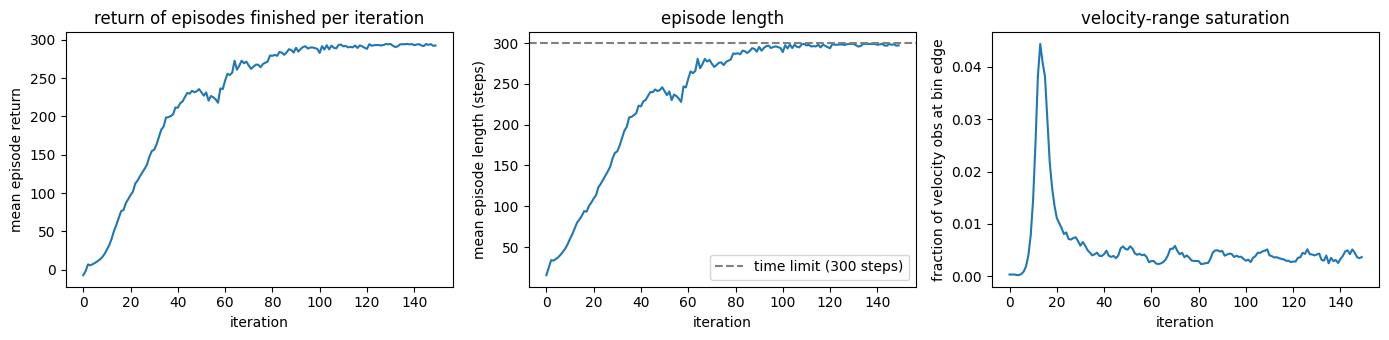

In [6]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 3, figsize=(14, 3.5))
axes[0].plot(history["iteration"], history["return"])
axes[0].set(xlabel="iteration", ylabel="mean episode return", title="return of episodes finished per iteration")
axes[1].plot(history["iteration"], history["length"])
axes[1].axhline(max_len, color="gray", ls="--", label=f"time limit ({max_len} steps)")
axes[1].set(xlabel="iteration", ylabel="mean episode length (steps)", title="episode length")
axes[1].legend()
axes[2].plot(history["iteration"], history["vel_sat"])
axes[2].set(xlabel="iteration", ylabel="fraction of velocity obs at bin edge", title="velocity-range saturation")
plt.tight_layout()
plt.show()

In [7]:
# deterministic rollout (argmax action token) of the trained policy; video embedded in the notebook (no file on disk)
from api.video import show

obs = env.reset()[0]["policy"]
prev_act = torch.full((NUM_ENVS,), BOS, dtype=torch.long, device=device)
frames = []
for _ in range(max_len):
    with torch.no_grad():
        action = ac(tokenize(prev_act, obs)[:, None]).argmax(-1)
    next_obs, _, terminated, truncated, _ = env.step(act_from_bin(action))
    obs = next_obs["policy"]
    prev_act = torch.where(terminated | truncated, torch.full_like(action, BOS), action)
    frames.append(env.render())
assert frames[0] is not None and getattr(frames[0], "ndim", 0) == 3, (
    f"env.render() returned {type(frames[0])}; the env must be created with render=True "
    "(isaac.launch(cameras=True) + make_env(render=True)) -- restart the kernel and rerun the setup cell"
)
show(frames, fps=round(1 / env.unwrapped.step_dt))

Great! it seems like there is still some jitter because the policy can't make very subtle actions (since there is a finite action space), but this could be addressed via a smarter tokenizer. 

We can proceed to experimenting with the setting of online in-context system identification. First, let's define a distribution over our env parameters. Some potential areas for randomization are:
- Actuator gain
- Pole mass
- Cart mass
- Pole length
- Cart friction

Claude mentioned that actuator gain and pole mass would be the simplest to implement, and we can do so by simply rescaling the current values log-uniformly by [0.5, 2.0]. 

To understand how a policy performs under *misspecification*, we can simplysample twice from the parameter distributions and use one for train and one for eval. In fact, we can consider the standard case - (1.0, 1.0) rescaling - our train and eval on a new draw. This allows us to re-use our policy trained above.


In [8]:
# domain randomization, resampled per env: actuator gain and pole mass rescaled log-uniformly, plus an action delay
# of 0-3 control steps (1 step = 1/60 s). (api/cartpole_dr.py holds the Isaac physics-view calls; gain 1, mass 1,
# delay 0 is the nominal system the policy trained on.) Pole mass gets a wider range than gain since it barely
# mattered within [0.5, 2].
from api.cartpole_dr import CartpoleRandomizer

rand = CartpoleRandomizer(env, gain_range=(0.5, 2.0), pole_mass_range=(0.2, 5.0), delay_range=(0, 3))
rand.resample()

# sanity checks: the draws cover the ranges, and the engine really applied the masses
print(f"gain      scales: min {rand.gain.min():.2f}  median {rand.gain.median():.2f}  max {rand.gain.max():.2f}")
print(f"pole mass scales: min {rand.pole_mass.min():.2f}  median {rand.pole_mass.median():.2f}  max {rand.pole_mass.max():.2f}")
print("delay (steps) counts:", torch.bincount(rand.delay, minlength=rand.delay_range[1] + 1).tolist())
applied = rand.applied_pole_mass_ratio()
print("max |applied - requested| pole mass ratio:", (applied - rand.pole_mass).abs().max().item())
assert torch.allclose(applied, rand.pole_mass, rtol=1e-3)

gain      scales: min 0.50  median 1.00  max 2.00
pole mass scales: min 0.20  median 0.99  max 5.00
delay (steps) counts: [1065, 1019, 1012, 1000]
max |applied - requested| pole mass ratio: 2.384185791015625e-07


nominal:            return  292.07 | ep len  296.1 / 300
random draw/env:    return  208.48 | ep len  224.2 / 300 | 64.4% survive the full episode


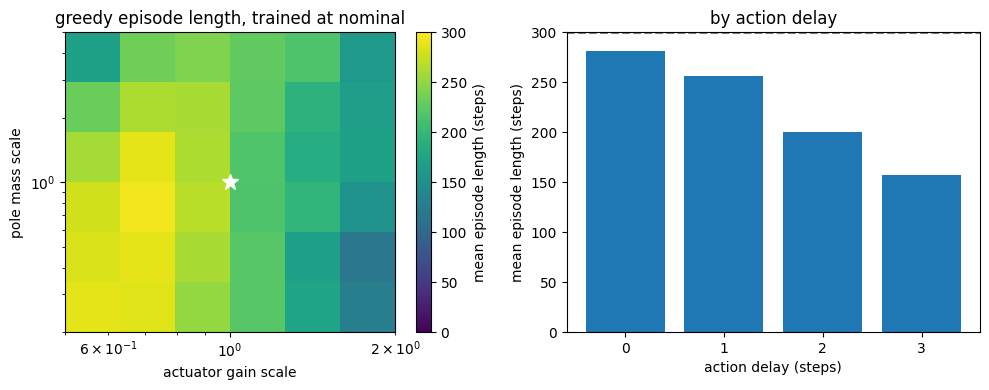

In [9]:
# out-of-domain eval of the policy trained above (it only ever saw the nominal system): one greedy episode per env,
# first on the nominal system, then on an independent random draw per env
import matplotlib.pyplot as plt
import numpy as np


def eval_episode():
    """One deterministic episode per env under the current rand parameters -> (return [N], length [N])."""
    obs = env.reset()[0]["policy"]
    rand.reset_buffer()  # delayed actions restart from zero force
    prev_act = torch.full((NUM_ENVS,), BOS, dtype=torch.long, device=device)
    alive = torch.ones(NUM_ENVS, dtype=torch.bool, device=device)
    ret = torch.zeros(NUM_ENVS, device=device)
    length = torch.zeros(NUM_ENVS, device=device)
    for _ in range(max_len):
        with torch.no_grad():
            action = ac(tokenize(prev_act, obs)[:, None]).argmax(-1)
        next_obs, reward, terminated, truncated, _ = env.step(rand.apply_action(act_from_bin(action)))
        ret += reward * alive
        length += alive
        done = terminated | truncated
        alive &= ~done  # the env auto-resets on done; only the first episode counts
        obs = next_obs["policy"]
        prev_act = torch.where(done, torch.full_like(action, BOS), action)
    return ret, length


rand.set(1.0, 1.0, 0)
nom_ret, nom_len = eval_episode()

rand.resample()
gain, pole_mass, delay = rand.gain.clone(), rand.pole_mass.clone(), rand.delay.clone()
ood_ret, ood_len = eval_episode()
print(f"nominal:            return {nom_ret.mean():7.2f} | ep len {nom_len.mean():6.1f} / {max_len}")
print(f"random draw/env:    return {ood_ret.mean():7.2f} | ep len {ood_len.mean():6.1f} / {max_len} "
      f"| {(ood_len >= max_len - 1).float().mean():.1%} survive the full episode")

# mean episode length over (gain, pole mass) (left; averaged over delays) and per delay (right)
g_edges = np.geomspace(*rand.gain_range, 7)
m_edges = np.geomspace(*rand.pole_mass_range, 7)
g, m, L = gain.cpu().numpy(), pole_mass.cpu().numpy(), ood_len.cpu().numpy()
sums, _, _ = np.histogram2d(g, m, bins=[g_edges, m_edges], weights=L)
counts, _, _ = np.histogram2d(g, m, bins=[g_edges, m_edges])
fig, (ax, ax2) = plt.subplots(1, 2, figsize=(10, 4))
im = ax.pcolormesh(g_edges, m_edges, (sums / np.maximum(counts, 1)).T, vmin=0, vmax=max_len)
ax.set(xscale="log", yscale="log", xlabel="actuator gain scale", ylabel="pole mass scale",
       title="greedy episode length, trained at nominal")
ax.plot(1.0, 1.0, "w*", ms=12)
fig.colorbar(im, ax=ax, label="mean episode length (steps)")
delays = np.arange(rand.delay_range[0], rand.delay_range[1] + 1)
ax2.bar(delays, [ood_len[delay == d].mean().item() for d in delays])
ax2.axhline(max_len - 1, color="gray", ls="--")
ax2.set(xlabel="action delay (steps)", ylabel="mean episode length (steps)", xticks=delays, ylim=(0, max_len),
        title="by action delay")
plt.tight_layout()
plt.show()

In [10]:
# caching for evaluation rollouts and videos, in the same on-disk cache as training (utils/experiment_cache.py).
# Evaluation results are keyed by the policy's weights digest, the system it ran on, and the settings below; videos are
# cached as encoded mp4 bytes (a few hundred KB; the raw frames would be hundreds of MB).
# A cache hit replays a FROZEN result: the env's random initial pole angles (and, for videos, the background envs) are
# not re-drawn, and the key cannot see code. Bump EVAL_VERSION when the eval/render code or camera changes meaning.
import hashlib

from api.video import encode_mp4, video_from_bytes

EVAL_VERSION = 1
EVAL_SEED = 0  # seeds the shared random system draw used by the comparison cells


def weights_digest(model):
    """Short hash of a model's weights, so a retrained policy never hits another policy's cached evaluation."""
    h = hashlib.sha256()
    for name, v in sorted(model.state_dict().items()):
        h.update(name.encode())
        h.update(v.detach().cpu().contiguous().numpy().tobytes())
    return h.hexdigest()[:16]


def _eval_context():
    return dict(version=EVAL_VERSION, task=TASK, num_envs=NUM_ENVS, max_len=max_len, seed=EVAL_SEED,
                dr=dict(gain=rand.gain_range, pole_mass=rand.pole_mass_range, delay=rand.delay_range))


def eval_cached(model, system, evaluator):
    """evaluator(model) -> (return [N], length [N]) under `system`, cached. system=None is the shared random draw
    (gain, pole_mass, delay globals, seeded by EVAL_SEED); otherwise a (gain, pole_mass, delay) tuple for every env."""
    params = dict(_eval_context(), weights=weights_digest(model), ctx=model.ctx, system="draw" if system is None else system)
    key = cache.make_key("cartpole_eval", params)
    hit = cache.get(key)
    if hit is None:
        if system is None:
            rand.set(gain, pole_mass, delay)
        else:
            rand.set(*system)
        ret, length = evaluator(model)
        cache.set(key, {"return": ret, "length": length}, experiment="cartpole_eval", params=params)
        return ret, length
    return hit["return"], hit["length"]


def video_cached(params, render, width=640):
    """render() -> (frames, fps, stats); returns (IPython Video, stats array). Only the mp4 and the stats are cached."""
    params = dict(_eval_context(), kind="video", **params)
    key = cache.make_key("cartpole_video", params)
    hit = cache.get(key)
    if hit is None:
        frames, fps, stats = render()
        hit = {"mp4": np.frombuffer(encode_mp4(frames, fps), dtype=np.uint8), "stats": np.asarray(stats, dtype=float)}
        cache.set(key, hit, experiment="cartpole_video", params=params)
    return video_from_bytes(hit["mp4"].tobytes(), width), hit["stats"]

In [11]:
# videos of env 0 under hand-picked (gain, pole mass, delay): nominal, then the two corners that push the system hardest
# (weak actuator + heavy pole, strong actuator + light pole, both at the longest delay). Greedy policy trained at nominal;
# videos embed in the notebook. Cached as mp4 bytes (see the eval-cache cell below); the other envs in the background
# keep whatever random draw was last set, and a cache hit replays that frozen video.
from IPython.display import display

ids0 = torch.tensor([0], device=device)
demo_settings = [
    (1.0, 1.0, 0),
    (rand.gain_range[0], rand.pole_mass_range[1], rand.delay_range[1]),
    (rand.gain_range[1], rand.pole_mass_range[0], rand.delay_range[1]),
]
for g0, m0, d0 in demo_settings:
    def render():
        obs = env.reset()[0]["policy"]
        rand.set(g0, m0, d0, ids0)  # only env 0 changes; it is the one the camera follows
        rand.reset_buffer()
        prev_act = torch.full((NUM_ENVS,), BOS, dtype=torch.long, device=device)
        frames, steps_alive, alive = [], 0, True
        for _ in range(max_len):
            with torch.no_grad():
                action = ac(tokenize(prev_act, obs)[:, None]).argmax(-1)
            next_obs, _, terminated, truncated, _ = env.step(rand.apply_action(act_from_bin(action)))
            done = terminated | truncated
            steps_alive += alive
            alive = alive and not bool(done[0])
            obs = next_obs["policy"]
            prev_act = torch.where(done, torch.full_like(action, BOS), action)
            frames.append(env.render())
        return frames, round(1 / env.unwrapped.step_dt), [[steps_alive]]

    video, stats = video_cached(
        dict(name="nominal-demo", policy=weights_digest(ac), system=(g0, m0, d0)), render, width=640
    )
    print(f"gain x{g0}, pole mass x{m0}, delay {d0}: env 0 lasted {int(stats[0][0])}/{max_len} steps")
    display(video)

gain x1.0, pole mass x1.0, delay 0: env 0 lasted 299/300 steps


gain x0.5, pole mass x5.0, delay 3: env 0 lasted 35/300 steps


gain x2.0, pole mass x0.2, delay 3: env 0 lasted 66/300 steps


Great, we can clearly see that the 2nd env struggles to keep the pole up, and the 3rd env even more so. Note that the cartpoles in the background of a video do not necessarily have the same parameters as what is in the front. This is why there are instances that fail in the background of video 1 above which is supposed to be the correctly specified setting. 

Now recall, that a markovian policy trained in a DR randomized environment may outperform a markovian policy trained in a non DR environment. The policy will *not* be able to identify what the system parameters are without a history, but it will be able to *hedge* against the potential randomization. 

NOTE: A further comment should be made that, in our instantiation, the previous action $a_{t-1}$ is technically included in $x_t$, but it may not contain all of the information that we need. We will need to check this though.

In the following cells we are going to re-run the exact training process as above but using a DR environment.

In [12]:
# the same training process, but every episode runs on a freshly randomized system (gain, pole mass, action delay from
# the `rand` distribution above). A new Markovian policy `ac_dr`; `ac` stays the nominal-trained one for comparison.
# It still can't identify the parameters (no history), only hedge against them. Cached like the nominal run, keyed
# additionally by the randomization ranges.
DR_EXPERIMENT = "cartpole_token_ppo_dr"
DR_PARAMS = dict(
    TRAIN_PARAMS,
    dr=dict(gain=rand.gain_range, pole_mass=rand.pole_mass_range, delay=rand.delay_range),
)

torch.manual_seed(SEED)
ac_dr = TokenActorCritic(**ARCH).to(device)
opt_dr = torch.optim.Adam(ac_dr.parameters(), lr=LR_INIT)

key_dr = cache.make_key(DR_EXPERIMENT, DR_PARAMS)
run_dr = cache.get(key_dr)
if run_dr is None:
    print(f"no cached run {key_dr}: training under domain randomization")
    run_dr = train(ac_dr, opt_dr, rand=rand)
    cache.set(key_dr, run_dr, experiment=DR_EXPERIMENT, params=DR_PARAMS)
else:
    print(f"loaded cached run {key_dr}")
ac_dr.load_state_dict(unpack_state_dict(run_dr, "ac.", device=device))
history_dr = {k[len("history."):]: v.tolist() for k, v in run_dr.items() if k.startswith("history.")}

loaded cached run ab5fd444e8af73c0


Let's compare the DR policy to the original policy when evaluated on the distribution of environments. Let's use mean return as our central measure, as well as return on some of the extreme environments. In a second cell let's also render some trajectories. 

over the randomized distribution (return, mean +- s.e.m. over envs; full episode = survived to the time limit):
  nominal-trained  return  205.22 +- 1.86 | ep len  221.3 / 300 | 62.6% full episodes
  DR-trained       return  273.80 +- 1.01 | ep len  280.7 / 300 | 91.0% full episodes
  DR - nominal return: +68.58 +- 2.03

return at the corners (every env set to the same system):
  setting               nominal-trained           DR-trained
  nominal                292.19 +- 0.46       294.96 +- 0.11
  g0.5/m0.2/d0           277.00 +- 0.96       251.13 +- 1.32
  g0.5/m0.2/d3           243.83 +- 1.52       240.17 +- 1.55
  g0.5/m5.0/d0           127.73 +- 1.92       147.15 +- 2.01
  g0.5/m5.0/d3            73.42 +- 1.73        97.16 +- 1.82
  g2.0/m0.2/d0           186.84 +- 1.77       273.26 +- 1.05
  g2.0/m0.2/d3            43.68 +- 0.56       162.01 +- 1.42
  g2.0/m5.0/d0           237.67 +- 1.78       295.06 +- 0.04
  g2.0/m5.0/d3            23.92 +- 0.49       259.99 +- 1.25


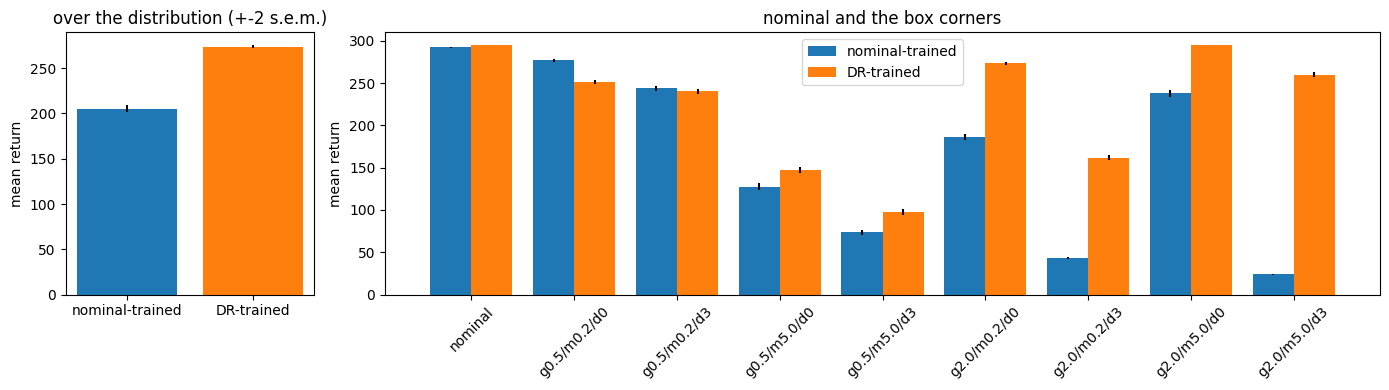

In [13]:
# compare the DR-trained policy `ac_dr` with the nominal-trained `ac` on the distribution of systems: greedy episodes,
# mean first-episode return as the headline number (paired on the same parameter draws), then the extreme corners of
# the randomization box. Initial pole angles are still random per episode, so paired envs differ in their start state.
import itertools

import matplotlib.pyplot as plt
import numpy as np

POLICIES = {"nominal-trained": ac, "DR-trained": ac_dr}


def eval_policy(model):
    """One greedy episode per env under the current rand parameters -> (return [N], length [N])."""
    obs = env.reset()[0]["policy"]
    rand.reset_buffer()  # delayed actions restart from zero force
    prev_act = torch.full((NUM_ENVS,), BOS, dtype=torch.long, device=device)
    alive = torch.ones(NUM_ENVS, dtype=torch.bool, device=device)
    ret = torch.zeros(NUM_ENVS, device=device)
    length = torch.zeros(NUM_ENVS, device=device)
    for _ in range(max_len):
        with torch.no_grad():
            action = model(tokenize(prev_act, obs)[:, None]).argmax(-1)
        next_obs, reward, terminated, truncated, _ = env.step(rand.apply_action(act_from_bin(action)))
        ret += reward * alive
        length += alive
        done = terminated | truncated
        alive &= ~done  # the env auto-resets on done; only the first episode counts
        obs = next_obs["policy"]
        prev_act = torch.where(done, torch.full_like(action, BOS), action)
    return ret.cpu().numpy(), length.cpu().numpy()


def mean_se(x):
    return x.mean(), x.std(ddof=1) / np.sqrt(len(x))


# 1) the distribution: one draw of NUM_ENVS systems, shared by both policies
torch.manual_seed(EVAL_SEED)  # the shared draw must be reproducible for the eval cache to hit
gain, pole_mass, delay = rand.sample(NUM_ENVS)
dist = {}
for name, model in POLICIES.items():
    dist[name] = eval_cached(model, None, eval_policy)
diff = dist["DR-trained"][0] - dist["nominal-trained"][0]
print("over the randomized distribution (return, mean +- s.e.m. over envs; full episode = survived to the time limit):")
for name, (ret, length) in dist.items():
    m, se = mean_se(ret)
    print(f"  {name:16s} return {m:7.2f} +- {se:.2f} | ep len {length.mean():6.1f} / {max_len} "
          f"| {(length >= max_len - 1).mean():.1%} full episodes")
m, se = mean_se(diff)
print(f"  DR - nominal return: {m:+.2f} +- {se:.2f}")

# 2) the corners of the box (every env set to the same system) plus the nominal system
settings = [("nominal", (1.0, 1.0, 0))] + [
    (f"g{g}/m{m_}/d{d}", (g, m_, d))
    for g, m_, d in itertools.product(rand.gain_range, rand.pole_mass_range, rand.delay_range)
]
corner = {name: {} for name, _ in settings}
for name, params in settings:
    for pname, model in POLICIES.items():
        corner[name][pname] = mean_se(eval_cached(model, params, eval_policy)[0])
print("\nreturn at the corners (every env set to the same system):")
print(f"  {'setting':16s} " + " ".join(f"{p:>20s}" for p in POLICIES))
for name, _ in settings:
    print(f"  {name:16s} " + " ".join(f"{corner[name][p][0]:12.2f} +- {corner[name][p][1]:4.2f}" for p in POLICIES))

fig, (ax, ax2) = plt.subplots(1, 2, figsize=(14, 4), gridspec_kw={"width_ratios": [1, 4]})
colors = ["tab:blue", "tab:orange"]
means = [mean_se(dist[p][0]) for p in POLICIES]
ax.bar(list(POLICIES), [mm for mm, _ in means], yerr=[2 * s for _, s in means], color=colors)
ax.set(ylabel="mean return", title="over the distribution (+-2 s.e.m.)")
x = np.arange(len(settings))
for k, (pname, color) in enumerate(zip(POLICIES, colors)):
    ax2.bar(x + (k - 0.5) * 0.4, [corner[n][pname][0] for n, _ in settings], 0.4,
            yerr=[2 * corner[n][pname][1] for n, _ in settings], color=color, label=pname)
ax2.set(xticks=x, xticklabels=[n for n, _ in settings], ylabel="mean return", title="nominal and the box corners")
ax2.tick_params(axis="x", rotation=45)
ax2.legend()
plt.tight_layout()
plt.show()

In [14]:
# trajectories: nominal-trained (left) vs DR-trained (right) on the same system, side by side. Every env is set to the same
# system so the background matches the foreground. Shown: nominal, then the corner that is worst for each policy.
# The two rollouts start from different random pole angles. Greedy actions; videos embed in the notebook. Cached as mp4
# bytes (see the eval-cache cell above): a hit replays the stored video.
import cv2
from IPython.display import display

corner_names = [n for n, _ in settings if n != "nominal"]
worst = {p: min(corner_names, key=lambda n: corner[n][p][0]) for p in POLICIES}
to_show = list(dict.fromkeys(["nominal", *worst.values()]))  # dedupe, keep order
params_of = dict(settings)


def render_rollout(model, system, label):
    """env 0's greedy episode on `system` (all envs share it) -> (labelled frames, steps survived, return)."""
    rand.set(*system)
    obs = env.reset()[0]["policy"]
    rand.reset_buffer()
    prev_act = torch.full((NUM_ENVS,), BOS, dtype=torch.long, device=device)
    frames, steps, ret, alive = [], 0, 0.0, True
    for _ in range(max_len):
        with torch.no_grad():
            action = model(tokenize(prev_act, obs)[:, None]).argmax(-1)
        next_obs, reward, terminated, truncated, _ = env.step(rand.apply_action(act_from_bin(action)))
        done = terminated | truncated
        steps += alive
        ret += float(reward[0]) * alive
        alive = alive and not bool(done[0])
        obs = next_obs["policy"]
        prev_act = torch.where(done, torch.full_like(action, BOS), action)
        frame = np.ascontiguousarray(env.render()).copy()
        cv2.putText(frame, label, (10, 28), cv2.FONT_HERSHEY_SIMPLEX, 0.9, (255, 255, 255), 2, cv2.LINE_AA)
        frames.append(frame)
    return frames, steps, ret


for name in to_show:
    def render():
        runs = {p: render_rollout(model, params_of[name], p) for p, model in POLICIES.items()}
        side_by_side = [np.concatenate([a, b], axis=1) for a, b in zip(*(frames for frames, _, _ in runs.values()))]
        stats = [[steps, ret] for _, steps, ret in runs.values()]
        return side_by_side, round(1 / env.unwrapped.step_dt), stats

    video, stats = video_cached(
        dict(name="side-by-side", policies={p: weights_digest(m) for p, m in POLICIES.items()}, system=params_of[name]),
        render, width=1000,
    )
    print(f"{name} (gain, pole mass, delay) = {params_of[name]}: "
          + " | ".join(f"{p}: {int(steps)}/{max_len} steps, return {ret:.1f}" for p, (steps, ret) in zip(POLICIES, stats)))
    display(video)

nominal (gain, pole mass, delay) = (1.0, 1.0, 0): nominal-trained: 299/300 steps, return 295.1 | DR-trained: 299/300 steps, return 297.7


g2.0/m5.0/d3 (gain, pole mass, delay) = (2.0, 5.0, 3): nominal-trained: 29/300 steps, return 5.2 | DR-trained: 299/300 steps, return 287.9


g0.5/m5.0/d3 (gain, pole mass, delay) = (0.5, 5.0, 3): nominal-trained: 299/300 steps, return 295.6 | DR-trained: 62/300 steps, return 23.6


Including a longer context window to allow for "in-context" system identification. We can modify our training procedure to main the last $K\in\{2, 5\}$ to give it the opportunity to see how previous actions were responded to by the environment and adjust the next action accordingly. Later on, we may want to include all previous steps in an environment, but that will likely create a training challenge to address later. 

For early steps in an environment, we can simply pre-pad $x = \big(\operatorname{bin}(0), x_0\big)$ in our sequence until we have the desired $K$-length context.

In [15]:
# long-context policies for in-context system identification: the same DR training, but the policy sees the last K steps
# (tokens [a_{t-1}, s_t] for each), K in {2, 5}; a new episode starts with its first step repeated to fill the window.
# K=1 is the Markovian `ac_dr` above. The critic is still the MLP on the current state. Cached per K like the other runs.
CTX_SIZES = (2, 5)
ac_ctx, history_ctx = {}, {}
for K in CTX_SIZES:
    arch = dict(ARCH, ctx=K)
    params = dict(DR_PARAMS, arch=arch)
    torch.manual_seed(SEED)
    model = TokenActorCritic(**arch).to(device)
    opt_k = torch.optim.Adam(model.parameters(), lr=LR_INIT)

    key_k = cache.make_key(DR_EXPERIMENT, params)
    run_k = cache.get(key_k)
    if run_k is None:
        print(f"K={K}: no cached run {key_k}: training ({sum(p.numel() for p in model.parameters()):,} parameters)")
        run_k = train(model, opt_k, rand=rand)
        cache.set(key_k, run_k, experiment=DR_EXPERIMENT, params=params)
    else:
        print(f"K={K}: loaded cached run {key_k}")
    model.load_state_dict(unpack_state_dict(run_k, "ac.", device=device))
    ac_ctx[K] = model
    history_ctx[K] = {k[len("history."):]: v.tolist() for k, v in run_k.items() if k.startswith("history.")}

K=2: loaded cached run b30973b7874762bc
K=5: loaded cached run 2cdaa607fc2be81f


It seems like the $K=5$ policy was still improving when training ended. It also seems like the returns are (in general) lower?

Let's run the same eval as above for both policies and make a plot with 4 bars for the overall (mean) return and box corners.

over the randomized distribution (return, mean +- s.e.m. over envs):
  nominal K=1        return  205.22 +- 1.86 | ep len  221.3 / 300 | 62.6% full episodes
  DR K=1             return  273.80 +- 1.01 | ep len  280.7 / 300 | 91.0% full episodes
  DR K=2             return  253.68 +- 1.44 | ep len  260.6 / 300 | 82.2% full episodes
  DR K=5             return  275.04 +- 0.99 | ep len  282.1 / 300 | 91.7% full episodes
  DR K=2 - DR K=1 return: -20.12 +- 1.52
  DR K=5 - DR K=1 return: +1.24 +- 1.33

return at the corners (every env set to the same system):
  setting                 nominal K=1               DR K=1               DR K=2               DR K=5
  nominal              292.19 +- 0.46       294.96 +- 0.11       292.16 +- 0.40       295.50 +- 0.08
  g0.5/m0.2/d0         277.00 +- 0.96       251.13 +- 1.32       240.79 +- 1.39       264.26 +- 1.15
  g0.5/m0.2/d3         243.83 +- 1.52       240.17 +- 1.55       218.99 +- 1.71       240.60 +- 1.52
  g0.5/m5.0/d0         127.73 +- 1.

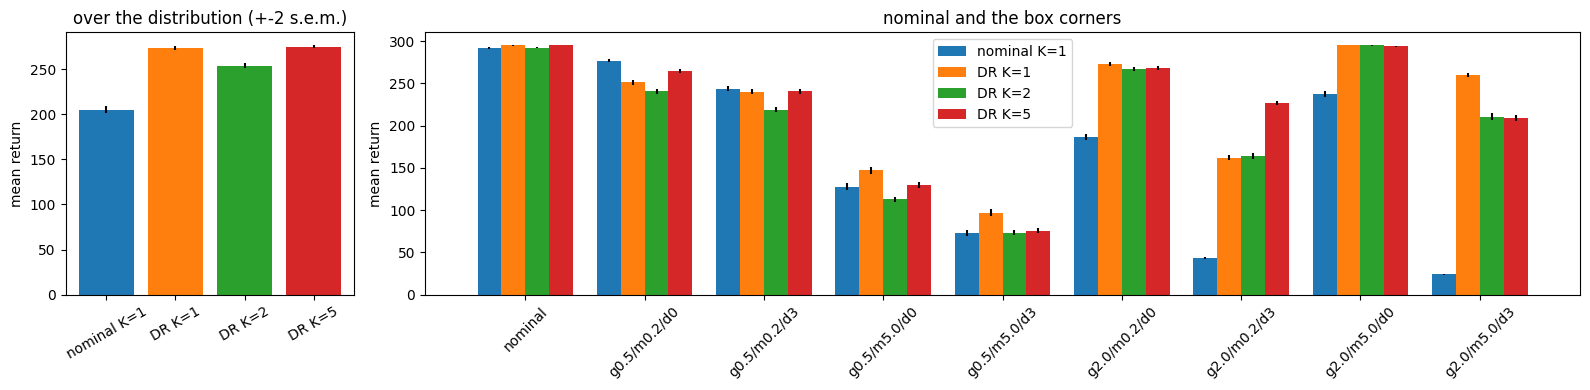

In [16]:
# the same evaluation for the long-context policies, next to the two K=1 policies. Reuses the previous comparison
# cell's results for those (same parameter draw, same corner settings), so run that cell first; only K=2 and K=5 are
# evaluated here. Greedy first-episode returns; four bars: nominal-trained K=1, DR-trained K=1, DR K=2, DR K=5.
# `report_comparison(labels)` prints and plots any set of evaluated policies.
assert all(n in globals() for n in ("dist", "corner", "settings", "gain", "pole_mass", "delay")), (
    "run the nominal-vs-DR comparison cell first"
)
NEW_POLICIES = {f"DR K={K}": ac_ctx[K] for K in CTX_SIZES}
LABELS = ["nominal K=1", "DR K=1", *NEW_POLICIES]


def eval_policy_ctx(model):
    """One greedy episode per env under the current rand parameters, with the model's K-step window -> (return, length)."""
    obs = env.reset()[0]["policy"]
    rand.reset_buffer()  # delayed actions restart from zero force
    prev_act = torch.full((NUM_ENVS,), BOS, dtype=torch.long, device=device)
    tokens = TokenHistory(NUM_ENVS, model.ctx)
    alive = torch.ones(NUM_ENVS, dtype=torch.bool, device=device)
    ret = torch.zeros(NUM_ENVS, device=device)
    length = torch.zeros(NUM_ENVS, device=device)
    for _ in range(max_len):
        with torch.no_grad():
            action = model(tokens.push(prev_act, obs)).argmax(-1)
        next_obs, reward, terminated, truncated, _ = env.step(rand.apply_action(act_from_bin(action)))
        ret += reward * alive
        length += alive
        done = terminated | truncated
        alive &= ~done  # the env auto-resets on done; only the first episode counts
        obs = next_obs["policy"]
        prev_act = torch.where(done, torch.full_like(action, BOS), action)
    return ret.cpu().numpy(), length.cpu().numpy()


# 1) the distribution: the same NUM_ENVS system draw as the previous comparison
all_dist = {"nominal K=1": dist["nominal-trained"], "DR K=1": dist["DR-trained"]}
for name, model in NEW_POLICIES.items():
    all_dist[name] = eval_cached(model, None, eval_policy_ctx)
# 2) the corners (every env set to the same system) plus the nominal system
all_corner = {
    n: {"nominal K=1": corner[n]["nominal-trained"], "DR K=1": corner[n]["DR-trained"]} for n, _ in settings
}
for name, params in settings:
    for pname, model in NEW_POLICIES.items():
        all_corner[name][pname] = mean_se(eval_cached(model, params, eval_policy_ctx)[0])


def report_comparison(labels):
    """Print the distribution and corner results for `labels` (keys of all_dist / all_corner) and plot them."""
    print("over the randomized distribution (return, mean +- s.e.m. over envs):")
    for name in labels:
        ret, length = all_dist[name]
        m, se = mean_se(ret)
        print(f"  {name:18s} return {m:7.2f} +- {se:.2f} | ep len {length.mean():6.1f} / {max_len} "
              f"| {(length >= max_len - 1).mean():.1%} full episodes")
    for name in labels:
        if name not in ("nominal K=1", "DR K=1"):
            m, se = mean_se(all_dist[name][0] - all_dist["DR K=1"][0])
            print(f"  {name} - DR K=1 return: {m:+.2f} +- {se:.2f}")

    print("\nreturn at the corners (every env set to the same system):")
    print(f"  {'setting':14s} " + " ".join(f"{p:>20s}" for p in labels))
    for name, _ in settings:
        print(f"  {name:14s} " + " ".join(f"{all_corner[name][p][0]:12.2f} +- {all_corner[name][p][1]:4.2f}" for p in labels))

    fig, (ax, ax2) = plt.subplots(1, 2, figsize=(16, 4), gridspec_kw={"width_ratios": [1, 4]})
    colors = [plt.cm.tab10(k) for k in range(len(labels))]
    means = [mean_se(all_dist[p][0]) for p in labels]
    ax.bar(labels, [mm for mm, _ in means], yerr=[2 * s for _, s in means], color=colors)
    ax.set(ylabel="mean return", title="over the distribution (+-2 s.e.m.)")
    ax.tick_params(axis="x", rotation=30)
    x = np.arange(len(settings))
    w = 0.8 / len(labels)
    for k, (pname, color) in enumerate(zip(labels, colors)):
        ax2.bar(x + (k - (len(labels) - 1) / 2) * w, [all_corner[n][pname][0] for n, _ in settings], w,
                yerr=[2 * all_corner[n][pname][1] for n, _ in settings], color=color, label=pname)
    ax2.set(xticks=x, xticklabels=[n for n, _ in settings], ylabel="mean return", title="nominal and the box corners")
    ax2.tick_params(axis="x", rotation=45)
    ax2.legend()
    plt.tight_layout()
    plt.show()


report_comparison(LABELS)

It seems like $K=5$ does not provide  as clear a direct benefit over $K=1$ as we might like. I hypothesize two reasons for this. 1) The action-state pair in the $K=1$ case already provides good information (though a clear counter-argument is that we don't know what state the action acted on) 2) the $K=5$ policy is undertrained. 

I am most interested in testing 2), and we can do it simply by training for an additional 150 steps and seeing if performance improves by adding a 5th bar to the above chart. 

no cached run e4c920ef25a0b8be: training K=5 from scratch for 300 iterations
it    0 | return   -6.11 | ep len  14.8 | pi -0.012 v 23.038 ent 3.34 kl 0.0079 lr 1.0e-03 | vel sat 0.450% | 28,563 steps/s
it   10 | return   15.75 | ep len  47.0 | pi -0.001 v 21.030 ent 3.18 kl 0.0058 lr 1.0e-03 | vel sat 2.078% | 32,410 steps/s
it   20 | return   69.38 | ep len  97.1 | pi +0.001 v 27.678 ent 2.92 kl 0.0113 lr 4.4e-04 | vel sat 5.433% | 33,089 steps/s
it   30 | return  108.18 | ep len 131.0 | pi -0.003 v 29.048 ent 2.81 kl 0.0040 lr 1.0e-03 | vel sat 5.529% | 33,775 steps/s
it   40 | return  146.33 | ep len 167.6 | pi +0.002 v 28.412 ent 2.75 kl 0.0134 lr 3.0e-04 | vel sat 4.128% | 33,948 steps/s
it   50 | return  174.58 | ep len 193.2 | pi -0.002 v 25.564 ent 2.71 kl 0.0017 lr 1.0e-03 | vel sat 4.202% | 33,563 steps/s
it   60 | return  166.25 | ep len 185.3 | pi -0.006 v 23.462 ent 2.65 kl 0.0047 lr 1.0e-03 | vel sat 3.524% | 33,713 steps/s
it   70 | return  181.27 | ep len 198.6 | pi -0.

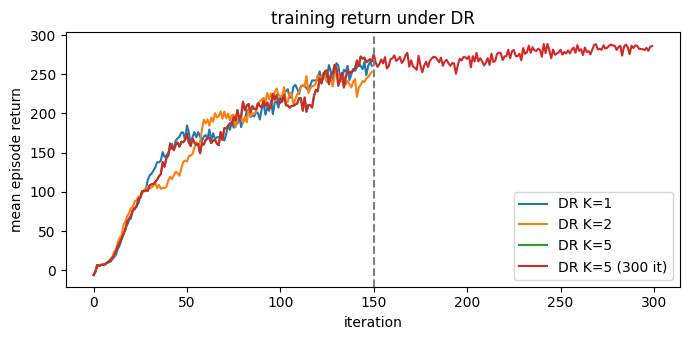

over the randomized distribution (return, mean +- s.e.m. over envs):
  nominal K=1        return  205.22 +- 1.86 | ep len  221.3 / 300 | 62.6% full episodes
  DR K=1             return  273.80 +- 1.01 | ep len  280.7 / 300 | 91.0% full episodes
  DR K=2             return  253.68 +- 1.44 | ep len  260.6 / 300 | 82.2% full episodes
  DR K=5             return  275.04 +- 0.99 | ep len  282.1 / 300 | 91.7% full episodes
  DR K=5 (300 it)    return  284.85 +- 0.79 | ep len  290.2 / 300 | 96.3% full episodes
  DR K=2 - DR K=1 return: -20.12 +- 1.52
  DR K=5 - DR K=1 return: +1.24 +- 1.33
  DR K=5 (300 it) - DR K=1 return: +11.05 +- 1.19

return at the corners (every env set to the same system):
  setting                 nominal K=1               DR K=1               DR K=2               DR K=5      DR K=5 (300 it)
  nominal              292.19 +- 0.46       294.96 +- 0.11       292.16 +- 0.40       295.50 +- 0.08       296.14 +- 0.04
  g0.5/m0.2/d0         277.00 +- 0.96       251.13 +- 1.3

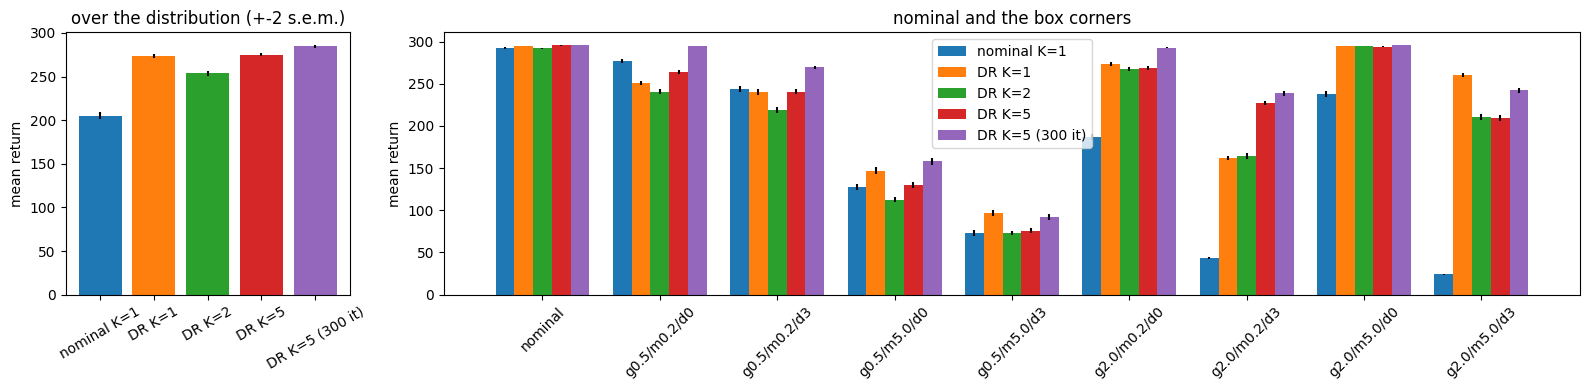

In [17]:
# test whether K=5 is undertrained: train a fresh K=5 policy for LONG_ITERS iterations (twice the ITERATIONS above, same
# seed and settings otherwise) and add it as a fifth policy, evaluated on the same system draw and corner settings as the
# others. Cached under its own key (the iteration count is part of the key).
assert "report_comparison" in globals(), "run the four-policy evaluation cell first"
LONG_ITERS = 2 * ITERATIONS
LONG = f"DR K=5 ({LONG_ITERS} it)"
arch5 = dict(ARCH, ctx=5)
params_long = dict(DR_PARAMS, arch=arch5, ppo=dict(DR_PARAMS["ppo"], iterations=LONG_ITERS))

torch.manual_seed(SEED)
ac_long = TokenActorCritic(**arch5).to(device)
opt_long = torch.optim.Adam(ac_long.parameters(), lr=LR_INIT)
key_long = cache.make_key(DR_EXPERIMENT, params_long)
run_long = cache.get(key_long)
if run_long is None:
    print(f"no cached run {key_long}: training K=5 from scratch for {LONG_ITERS} iterations")
    run_long = train(ac_long, opt_long, rand=rand, iterations=LONG_ITERS)
    cache.set(key_long, run_long, experiment=DR_EXPERIMENT, params=params_long)
else:
    print(f"loaded cached run {key_long}")
ac_long.load_state_dict(unpack_state_dict(run_long, "ac.", device=device))
history_long = {k[len("history."):]: v.tolist() for k, v in run_long.items() if k.startswith("history.")}

# training curves (sampled-action returns on the DR distribution) for context
fig, ax = plt.subplots(figsize=(7, 3.5))
for label, h in [("DR K=1", history_dr), ("DR K=2", history_ctx[2]), ("DR K=5", history_ctx[5]), (LONG, history_long)]:
    ax.plot(h["iteration"], h["return"], label=label)
ax.axvline(ITERATIONS, color="gray", ls="--")  # where the other runs stopped
ax.set(xlabel="iteration", ylabel="mean episode return", title="training return under DR")
ax.legend()
plt.tight_layout()
plt.show()

# evaluate on the same draw and corners as the other policies, then redraw the comparison with five bars
all_dist[LONG] = eval_cached(ac_long, None, eval_policy_ctx)
for name, params in settings:
    all_corner[name][LONG] = mean_se(eval_cached(ac_long, params, eval_policy_ctx)[0])
report_comparison([*LABELS, LONG])